In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving predictive_maintenance_v3.csv to predictive_maintenance_v3.csv


In [ ]:
import os
print(os.listdir())

['.config', 'predictive_maintenance_v3.csv', 'sample_data']


In [ ]:
import pandas as pd

# Loading dataset
df = pd.read_csv("/content/predictive_maintenance_v3.csv")

# Display first 5 rows
print(df.head())

# Display dataset shape
print("Shape:", df.shape)

# Display column names
print("Columns:", df.columns.tolist())

             timestamp  machine_id machine_type  vibration_rms  \
0  2024-01-01 00:00:00           1          CNC           0.81   
1  2024-01-01 00:03:00           1          CNC           0.75   
2  2024-01-01 00:21:00           1          CNC           0.71   
3  2024-01-01 00:45:00           1          CNC           0.76   
4  2024-01-01 00:54:00           1          CNC           0.88   

   temperature_motor  current_phase_avg  pressure_level    rpm operating_mode  \
0              49.51               5.10            23.6  860.9           idle   
1              40.58               5.30            23.6  899.6           idle   
2              49.70                NaN            21.3  862.7           idle   
3              43.04               4.79            22.6  870.4           idle   
4              41.39               4.44            22.2  881.9           idle   

   hours_since_maintenance  ambient_temp  rul_hours  failure_within_24h  \
0                   273.80          13.9 

In [ ]:
# Displaying dataset info
df.info()

# Checking missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Checking duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Displaying statistical summary
print("\nStatistical Summary:")
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24042 entries, 0 to 24041
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                24042 non-null  object 
 1   machine_id               24042 non-null  int64  
 2   machine_type             24042 non-null  object 
 3   vibration_rms            23042 non-null  float64
 4   temperature_motor        23208 non-null  float64
 5   current_phase_avg        23311 non-null  float64
 6   pressure_level           23118 non-null  float64
 7   rpm                      23509 non-null  float64
 8   operating_mode           24042 non-null  object 
 9   hours_since_maintenance  24042 non-null  float64
 10  ambient_temp             24042 non-null  float64
 11  rul_hours                24042 non-null  float64
 12  failure_within_24h       24042 non-null  int64  
 13  failure_type             24042 non-null  object 
 14  estimated_repair_cost 

In [ ]:
# Create a copy of the dataset
data = df.copy()

# Timestamp into datetime (format)
data["timestamp"] = pd.to_datetime(data["timestamp"])

# Extracting time features
data["hour"] = data["timestamp"].dt.hour
data["day"] = data["timestamp"].dt.day
data["month"] = data["timestamp"].dt.month

# Fill missing numerical values with their median
numerical_cols = [
    "vibration_rms",
    "temperature_motor",
    "current_phase_avg",
    "pressure_level",
    "rpm"
]

for col in numerical_cols:
    data[col] = data[col].fillna(data[col].median())

# Checking for missing values after preprocessing
print("Missing values after preprocessing:")
print(data.isnull().sum())

# Display the processed dataset
print("\nProcessed Dataset:")
print(data.head())

Missing values after preprocessing:
timestamp                  0
machine_id                 0
machine_type               0
vibration_rms              0
temperature_motor          0
current_phase_avg          0
pressure_level             0
rpm                        0
operating_mode             0
hours_since_maintenance    0
ambient_temp               0
rul_hours                  0
failure_within_24h         0
failure_type               0
estimated_repair_cost      0
hour                       0
day                        0
month                      0
dtype: int64

Processed Dataset:
            timestamp  machine_id machine_type  vibration_rms  \
0 2024-01-01 00:00:00           1          CNC           0.81   
1 2024-01-01 00:03:00           1          CNC           0.75   
2 2024-01-01 00:21:00           1          CNC           0.71   
3 2024-01-01 00:45:00           1          CNC           0.76   
4 2024-01-01 00:54:00           1          CNC           0.88   

   temperature_mot

In [ ]:
# Select input features
features = [
    "machine_type",
    "vibration_rms",
    "temperature_motor",
    "current_phase_avg",
    "pressure_level",
    "rpm",
    "operating_mode",
    "hours_since_maintenance",
    "ambient_temp",
    "hour",
    "day",
    "month"
]

# Input data
X = data[features]

# Target variable
y = data["rul_hours"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (24042, 12)
Target shape: (24042,)


In [ ]:
#testing and training data
from sklearn.model_selection import GroupShuffleSplit

# Spliting data by machine_id
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=data["machine_id"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (19240, 12)
Testing data: (4802, 12)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate numerical and categorical columns
categorical_cols = ["machine_type", "operating_mode"]

numerical_cols = [
    col for col in features if col not in categorical_cols]

# Preprocessing numerical data
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Preprocessing completed.")

Preprocessing completed.


In [ ]:
from sklearn.tree import DecisionTreeRegressor

#Decision Tree model
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
])

# Training the model
dt_model.fit(X_train, y_train)

# Predictions making
dt_pred = dt_model.predict(X_test)

print("Decision Tree training completed!")

Decision Tree training completed!


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest model
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

# Training the model
rf_model.fit(X_train, y_train)

# Predictions making
rf_pred = rf_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

# Evaluation function
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

# Evaluating both models
results = []

results.append(
    evaluate_model("Decision Tree", y_test, dt_pred)
)

results.append(
    evaluate_model("Random Forest", y_test, rf_pred)
)

# Comparison output
results_df = pd.DataFrame(results)
print(results_df)

           Model        MAE       RMSE  R2 Score
0  Decision Tree   9.681713  15.059117  0.678088
1  Random Forest  10.111490  14.807150  0.688770


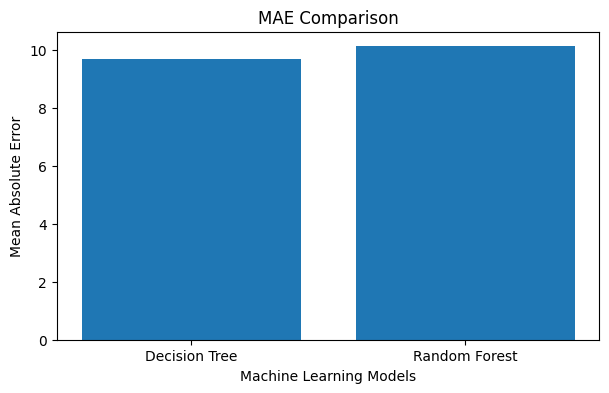

In [ ]:
import matplotlib.pyplot as plt

# Plot MAE comparison
plt.figure(figsize=(7, 4))

plt.bar(results_df["Model"], results_df["MAE"])

plt.title("MAE Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error")
plt.show()

Please select predictive_maintenance_v3.csv


Saving predictive_maintenance_v3.csv to predictive_maintenance_v3.csv

Dataset loaded: predictive_maintenance_v3.csv
Dataset shape: (24042, 15)
Training rows: 16405
Testing rows: 4122
Training machines: 16
Testing machines: 4

Training Decision Tree...

Training Random Forest...

MODEL EVALUATION RESULTS
        Model     MAE    RMSE  R2 Score
Decision Tree 11.3686 16.0312    0.6203
Random Forest 11.5072 15.8112    0.6307


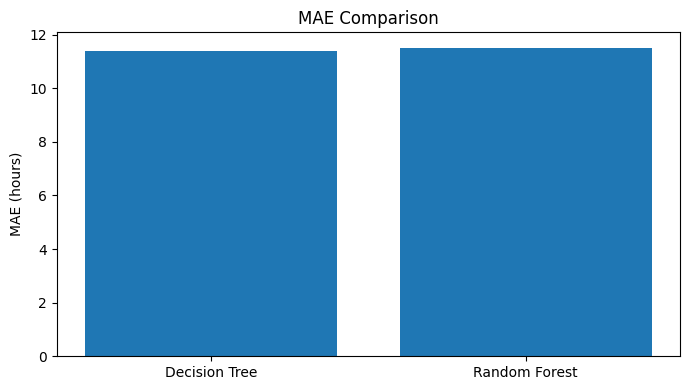

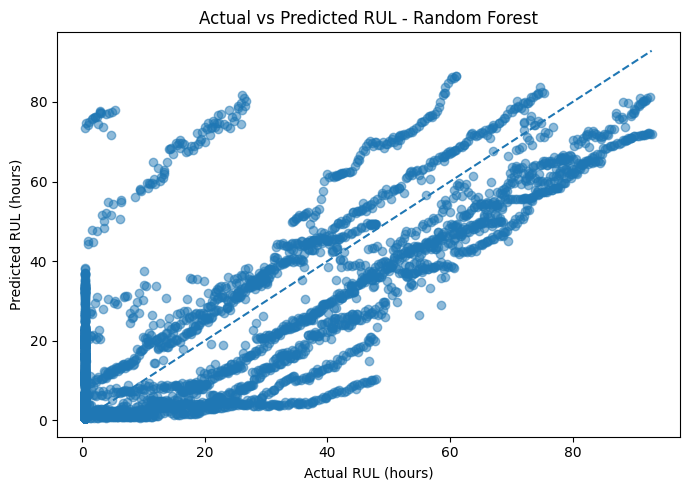


Example predicted RUL: 86.45 hours
Actual RUL: 61.0 hours

SUCCESS: Both models trained and results saved.
Next: download your notebook and project files for GitHub.


In [6]:

# COMPLETE PROJECT RECOVERY AND TRAINING CELL

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from google.colab import files
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Upload the dataset
print("Please select predictive_maintenance_v3.csv")
uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload the dataset as a CSV file.")

df = pd.read_csv(csv_files[0])
print("\nDataset loaded:", csv_files[0])
print("Dataset shape:", df.shape)

# 2. Prepare the dataset
data = df.copy()
data["timestamp"] = pd.to_datetime(data["timestamp"], errors="coerce")

data["hour"] = data["timestamp"].dt.hour
data["day"] = data["timestamp"].dt.day
data["month"] = data["timestamp"].dt.month

features = [
    "machine_type",
    "vibration_rms",
    "temperature_motor",
    "current_phase_avg",
    "pressure_level",
    "rpm",
    "operating_mode",
    "hours_since_maintenance",
    "ambient_temp",
    "hour",
    "day",
    "month"
]

# Remove records with missing target or unusable timestamp
data = data.dropna(subset=["rul_hours", "timestamp"]).copy()

X = data[features]
y = data["rul_hours"]
groups = data["machine_id"]

# 3. Split by machine to reduce data leakage
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training machines:", groups.iloc[train_idx].nunique())
print("Testing machines:", groups.iloc[test_idx].nunique())

# 4. Preprocessing pipeline
categorical_cols = ["machine_type", "operating_mode"]
numerical_cols = [c for c in features if c not in categorical_cols]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# 5. Train the two syllabus-friendly models
models = {
    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(max_depth=10, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

predictions = {}
results = []

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 Score": r2_score(y_test, pred)
    })

    safe_name = name.lower().replace(" ", "_")
    joblib.dump(model, f"{safe_name}_rul_model.pkl")

# 6. Display and save results
results_df = pd.DataFrame(results)
print("\nMODEL EVALUATION RESULTS")
print(results_df.round(4).to_string(index=False))
results_df.to_csv("model_evaluation_results.csv", index=False)

# 7. Plot MAE comparison
plt.figure(figsize=(7, 4))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("MAE Comparison")
plt.ylabel("MAE (hours)")
plt.tight_layout()
plt.savefig("mae_comparison.png", dpi=150)
plt.show()

# 8. Actual vs predicted RUL for Random Forest
rf_pred = predictions["Random Forest"]

plt.figure(figsize=(7, 5))
plt.scatter(y_test, rf_pred, alpha=0.5)
low = min(y_test.min(), rf_pred.min())
high = max(y_test.max(), rf_pred.max())
plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual RUL (hours)")
plt.ylabel("Predicted RUL (hours)")
plt.title("Actual vs Predicted RUL - Random Forest")
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

# 9. Example prediction
sample = X_test.iloc[[0]]
print("\nExample predicted RUL:",
      round(models["Random Forest"].predict(sample)[0], 2), "hours")
print("Actual RUL:", round(y_test.iloc[0], 2), "hours")

# 10. Save a copy of the dataset and all results in one folder
os.makedirs("predictive_maintenance_project", exist_ok=True)

for filename in [
    "decision_tree_rul_model.pkl",
    "random_forest_rul_model.pkl",
    "model_evaluation_results.csv",
    "mae_comparison.png",
    "actual_vs_predicted.png"
]:
    if os.path.exists(filename):
        import shutil
        shutil.copy(filename, "predictive_maintenance_project")

print("\nSUCCESS: Both models trained and results saved.")
print("Next: download your notebook and project files for GitHub.")


In [7]:
print(results_df.round(4).to_string(index=False))

        Model     MAE    RMSE  R2 Score
Decision Tree 11.3686 16.0312    0.6203
Random Forest 11.5072 15.8112    0.6307


In [8]:
import os
import shutil

project = "/content/predictive_maintenance_project"
os.makedirs(project, exist_ok=True)

# Copy available project outputs
files_to_copy = [
    "decision_tree_rul_model.pkl",
    "random_forest_rul_model.pkl",
    "model_evaluation_results.csv",
    "mae_comparison.png",
    "actual_vs_predicted.png"
]

for filename in files_to_copy:
    if os.path.exists(filename):
        shutil.copy(filename, project)

# Requirements
with open(os.path.join(project, "requirements.txt"), "w") as f:
    f.write(
        "pandas\nnumpy\nmatplotlib\nscikit-learn\njoblib\n"
    )

# README
readme = """# Predictive Maintenance of Industrial Machines

## Project Objective
Predict the Remaining Useful Life (RUL) of industrial machines
in hours using machine sensor data.

## Dataset
The dataset contains sensor readings and the target column
`rul_hours`. The CSV is not included in this package.

## Machine Learning Models
- Decision Tree Regressor
- Random Forest Regressor

## Workflow
1. Load and inspect the dataset.
2. Handle missing sensor readings.
3. Extract time features.
4. Split records by machine ID into training and testing data.
5. Train regression models.
6. Evaluate MAE, RMSE and R2 Score.
7. Visualize predictions and model performance.

## Evaluation
See `model_evaluation_results.csv` for the measured results.

## Files
- Saved model files: trained regression pipelines
- `mae_comparison.png`: MAE comparison graph
- `actual_vs_predicted.png`: Random Forest prediction graph
- `model_evaluation_results.csv`: evaluation metrics

## Installation
Run `pip install -r requirements.txt`.

The original dataset and training notebook are needed to
reproduce the model training.
"""

with open(os.path.join(project, "README.md"), "w") as f:
    f.write(readme)

# Package the project
zip_path = shutil.make_archive(
    "/content/predictive_maintenance_project",
    "zip",
    project
)

print("Project files:")
print(os.listdir(project))
print("\nZIP created:", zip_path)

Project files:
['random_forest_rul_model.pkl', 'mae_comparison.png', 'model_evaluation_results.csv', 'requirements.txt', 'actual_vs_predicted.png', 'decision_tree_rul_model.pkl', 'README.md']

ZIP created: /content/predictive_maintenance_project.zip


In [10]:
from google.colab import files

files.download("/content/predictive_maintenance_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
print("Dataset loaded:", "df" in globals())
print("Training data available:", "X_train" in globals())
print("Testing data available:", "X_test" in globals())
print("Decision Tree trained:", "dt_model" in globals())
print("Random Forest trained:", "rf_model" in globals())
print("Evaluation results available:", "results_df" in globals())

Dataset loaded: True
Training data available: True
Testing data available: True
Decision Tree trained: False
Random Forest trained: False
Evaluation results available: True


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [14]:
print("Available model variables:")

for name in ["models", "dt_model", "rf_model", "lr_model",
             "X_train", "X_test", "y_train", "y_test",
             "lr_pred", "results_df"]:
    print(name, "->", name in globals())

if "models" in globals():
    print("\nModels inside dictionary:", list(models.keys()))

Available model variables:
models -> True
dt_model -> False
rf_model -> False
lr_model -> True
X_train -> True
X_test -> True
y_train -> True
y_test -> True
lr_pred -> True
results_df -> True

Models inside dictionary: ['Decision Tree', 'Random Forest']


In [15]:
dt_model = models["Decision Tree"]
rf_model = models["Random Forest"]

print("Decision Tree and Random Forest variables restored!")

Decision Tree and Random Forest variables restored!


In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Get the trained models
dt_model = models["Decision Tree"]
rf_model = models["Random Forest"]

# Generate predictions
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Compare all three models
predictions = {
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Linear Regression": lr_pred
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 Score": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")
print(results_df.round(4).to_string(index=False))

MODEL COMPARISON RESULTS
            Model     MAE    RMSE  R2 Score
    Decision Tree 11.3686 16.0312    0.6203
    Random Forest 11.5072 15.8112    0.6307
Linear Regression 19.2799 24.2610    0.1305


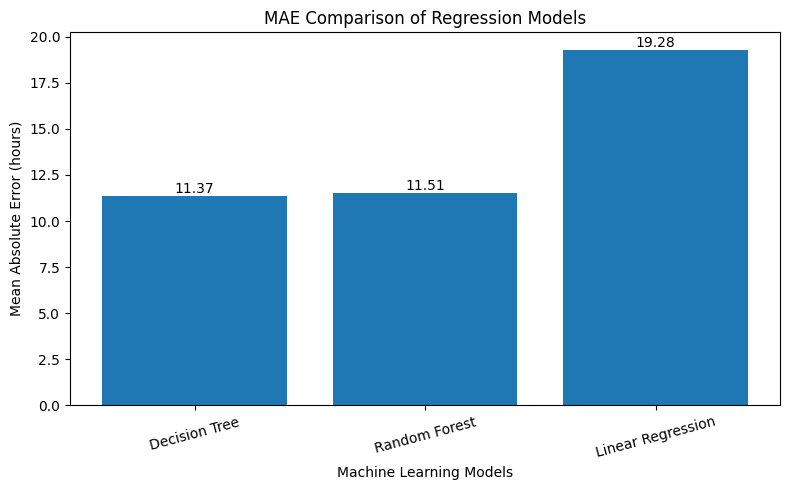

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.title("MAE Comparison of Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error (hours)")
plt.xticks(rotation=15)

# Display the MAE value above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("mae_comparison.png", dpi=150)
plt.show()

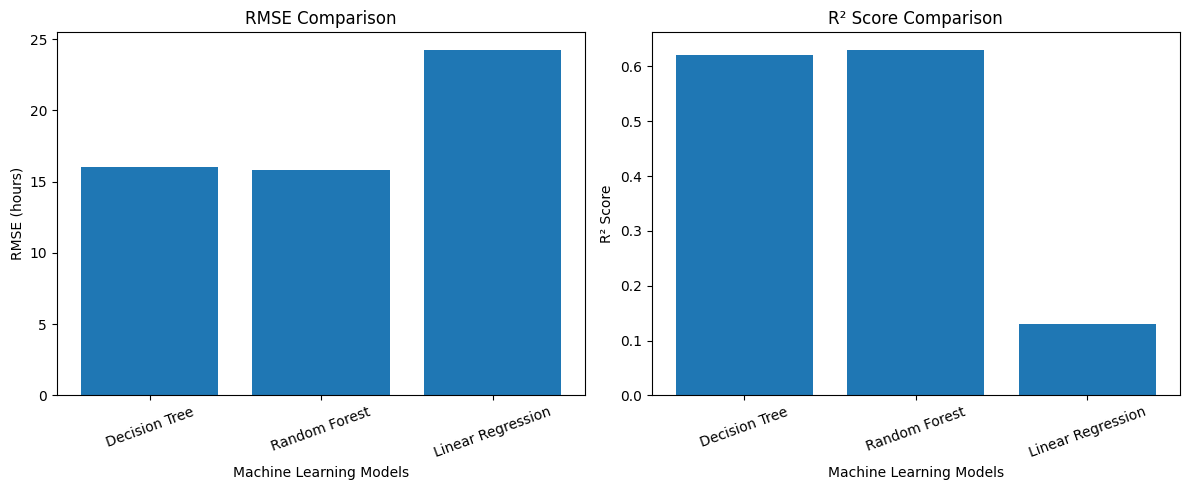

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# RMSE comparison
axes[0].bar(results_df["Model"], results_df["RMSE"])
axes[0].set_title("RMSE Comparison")
axes[0].set_xlabel("Machine Learning Models")
axes[0].set_ylabel("RMSE (hours)")
axes[0].tick_params(axis="x", rotation=20)

# R² comparison
axes[1].bar(results_df["Model"], results_df["R2 Score"])
axes[1].set_title("R² Score Comparison")
axes[1].set_xlabel("Machine Learning Models")
axes[1].set_ylabel("R² Score")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("model_metrics_comparison.png", dpi=150)
plt.show()

In [20]:
print("FINAL MODEL COMPARISON")
display(results_df.round(4))

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Decision Tree,11.3686,16.0312,0.6203
1,Random Forest,11.5072,15.8112,0.6307
2,Linear Regression,19.2799,24.2610,0.1305


In [21]:
results_df.to_csv("model_evaluation_results.csv", index=False)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [22]:
from sklearn.model_selection import GroupShuffleSplit

# Features for classification
classification_features = [
    "machine_type",
    "vibration_rms",
    "temperature_motor",
    "current_phase_avg",
    "pressure_level",
    "rpm",
    "operating_mode",
    "hours_since_maintenance",
    "ambient_temp",
    "hour",
    "day",
    "month"
]

X_class = data[classification_features]
y_class = data["failure_within_24h"]
groups_class = data["machine_id"]

# Split by machine ID
splitter_class = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter_class.split(X_class, y_class, groups=groups_class)
)

Xc_train = X_class.iloc[train_idx]
Xc_test = X_class.iloc[test_idx]
yc_train = y_class.iloc[train_idx]
yc_test = y_class.iloc[test_idx]

print("Classification data prepared!")
print("Training rows:", len(Xc_train))
print("Testing rows:", len(Xc_test))
print("\nTarget distribution:")
print(y_class.value_counts())

Classification data prepared!
Training rows: 16405
Testing rows: 4122

Target distribution:
failure_within_24h
0    17047
1     3480
Name: count, dtype: int64


In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

categorical_cols_class = ["machine_type", "operating_mode"]

numerical_cols_class = [
    col for col in classification_features
    if col not in categorical_cols_class
]

preprocessor_class = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_cols_class),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols_class)
])

classifier = Pipeline([
    ("preprocessor", preprocessor_class),
    ("model", DecisionTreeClassifier(
        max_depth=8,
        random_state=42,
        class_weight="balanced"
    ))
])

classifier.fit(Xc_train, yc_train)

yc_pred = classifier.predict(Xc_test)

print("Decision Tree Classifier trained successfully!")

Decision Tree Classifier trained successfully!


Accuracy: 0.9083
Precision: 0.5485
Recall: 0.7182
F1 Score: 0.622

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.93      0.95      3689
           1       0.55      0.72      0.62       433

    accuracy                           0.91      4122
   macro avg       0.76      0.82      0.78      4122
weighted avg       0.92      0.91      0.91      4122



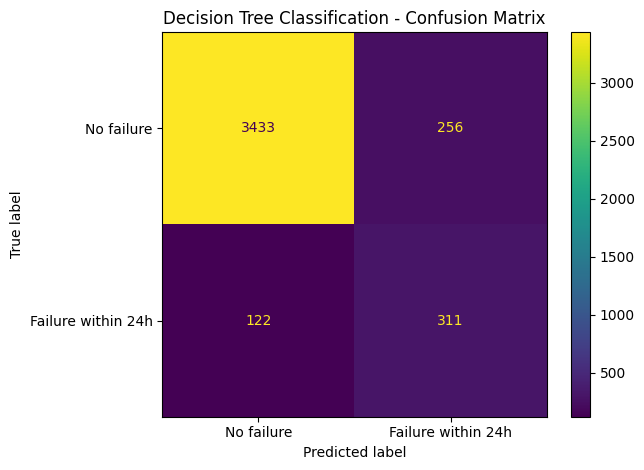

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Accuracy:", round(accuracy_score(yc_test, yc_pred), 4))
print("Precision:", round(
    precision_score(yc_test, yc_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(yc_test, yc_pred, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(yc_test, yc_pred, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(yc_test, yc_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    yc_test,
    yc_pred,
    display_labels=["No failure", "Failure within 24h"]
)

plt.title("Decision Tree Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [25]:
import joblib

joblib.dump(classifier, "failure_classifier.pkl")

print("Classification model saved successfully!")

Classification model saved successfully!


In [26]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Regression results
print("REGRESSION MODEL COMPARISON")
display(results_df.round(4))

# Classification results
classification_results = pd.DataFrame([{
    "Model": "Decision Tree Classifier",
    "Accuracy": accuracy_score(yc_test, yc_pred),
    "Precision": precision_score(yc_test, yc_pred, zero_division=0),
    "Recall": recall_score(yc_test, yc_pred, zero_division=0),
    "F1 Score": f1_score(yc_test, yc_pred, zero_division=0)
}])

print("CLASSIFICATION MODEL RESULTS")
display(classification_results.round(4))

classification_results.to_csv(
    "classification_evaluation_results.csv", index=False
)

REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Decision Tree,11.3686,16.0312,0.6203
1,Random Forest,11.5072,15.8112,0.6307
2,Linear Regression,19.2799,24.2610,0.1305


CLASSIFICATION MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree Classifier,0.9083,0.5485,0.7182,0.622


                         Feature  Importance
1         num__temperature_motor    0.353471
4                       num__rpm    0.325888
2         num__current_phase_avg    0.104251
0             num__vibration_rms    0.101897
3            num__pressure_level    0.042152
9                     num__month    0.027150
16      cat__operating_mode_peak    0.016857
5   num__hours_since_maintenance    0.010226
15    cat__operating_mode_normal    0.008960
11  cat__machine_type_Compressor    0.003572


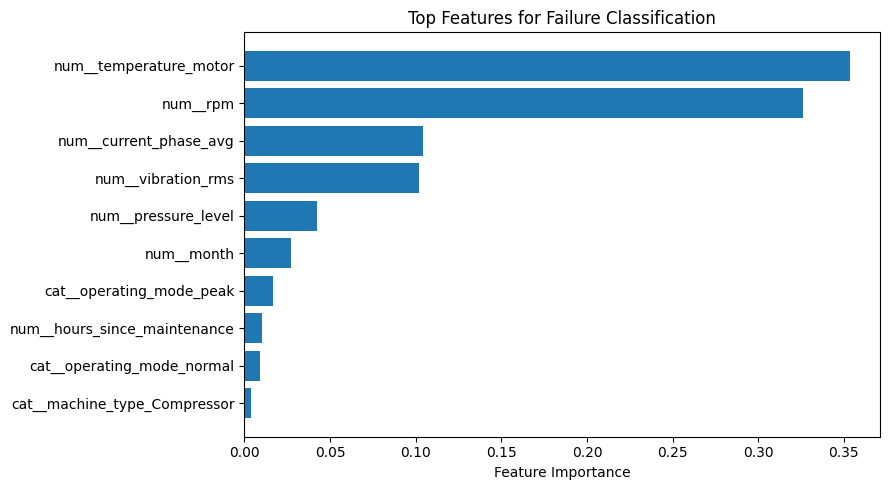

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

feature_names = (
    classifier.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    classifier.named_steps["model"].feature_importances_
)

classification_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(classification_importance.head(10))

top = classification_importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 5))
plt.barh(top["Feature"], top["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top Features for Failure Classification")
plt.tight_layout()
plt.savefig("classification_feature_importance.png", dpi=150)
plt.show()

In [28]:
import os

for filename in [
    "decision_tree_rul_model.pkl",
    "random_forest_rul_model.pkl",
    "linear_regression_rul_model.pkl",
    "failure_classifier.pkl",
    "model_evaluation_results.csv",
    "classification_evaluation_results.csv",
    "mae_comparison.png",
    "model_metrics_comparison.png",
    "actual_vs_predicted.png",
    "confusion_matrix.png",
    "classification_feature_importance.png"
]:
    print(
        f"{'✓' if os.path.exists(filename) else 'Missing'} {filename}"
    )

✓ decision_tree_rul_model.pkl
✓ random_forest_rul_model.pkl
Missing linear_regression_rul_model.pkl
✓ failure_classifier.pkl
✓ model_evaluation_results.csv
✓ classification_evaluation_results.csv
✓ mae_comparison.png
✓ model_metrics_comparison.png
✓ actual_vs_predicted.png
✓ confusion_matrix.png
✓ classification_feature_importance.png


In [29]:
import os
import shutil

project_dir = "/content/predictive_maintenance_project"
os.makedirs(project_dir, exist_ok=True)

files_to_copy = [
    "decision_tree_rul_model.pkl",
    "random_forest_rul_model.pkl",
    "linear_regression_rul_model.pkl",
    "failure_classifier.pkl",
    "model_evaluation_results.csv",
    "classification_evaluation_results.csv",
    "mae_comparison.png",
    "model_metrics_comparison.png",
    "actual_vs_predicted.png",
    "confusion_matrix.png",
    "classification_feature_importance.png"
]

for filename in files_to_copy:
    if os.path.exists(filename):
        shutil.copy(filename, project_dir)
    else:
        print("Not found:", filename)

print("\nProject files:")
print(os.listdir(project_dir))

Not found: linear_regression_rul_model.pkl

Project files:
['random_forest_rul_model.pkl', 'classification_feature_importance.png', 'mae_comparison.png', 'classification_evaluation_results.csv', 'confusion_matrix.png', 'model_evaluation_results.csv', 'requirements.txt', 'model_metrics_comparison.png', 'actual_vs_predicted.png', 'failure_classifier.pkl', 'decision_tree_rul_model.pkl', 'README.md']


In [30]:
requirements = """pandas
numpy
matplotlib
scikit-learn
joblib
"""

with open(os.path.join(project_dir, "requirements.txt"), "w") as f:
    f.write(requirements)

readme = """# Predictive Maintenance of Industrial Machines

## Project Objective
Predict the Remaining Useful Life (RUL) of industrial machines
and classify whether a machine may experience failure within 24 hours.

## Machine Learning Models
### Regression
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor

### Classification
- Decision Tree Classifier

## Evaluation Metrics
Regression:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R2 Score

Classification:
- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix

## Project Workflow
1. Dataset inspection
2. Data preprocessing
3. Feature selection
4. Training and testing
5. Model evaluation
6. Prediction and visualization

## Files
- predictive_maintenance.ipynb: Complete project implementation
- Saved model files: Trained machine learning pipelines
- CSV files: Evaluation results
- PNG files: Model evaluation graphs

## Installation
Install dependencies using:
pip install -r requirements.txt

Note: The original dataset is not included. Provide the CSV file
when rerunning the notebook. Actual model performance is reported
in the evaluation CSV files.
"""

with open(os.path.join(project_dir, "README.md"), "w") as f:
    f.write(readme)

print("README.md and requirements.txt created!")

README.md and requirements.txt created!


In [31]:
import shutil

zip_path = shutil.make_archive(
    "/content/predictive_maintenance_project",
    "zip",
    project_dir
)

from google.colab import files
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>